# Análisis de sentimiento de reseñas con una RNN (LSTM bidireccional)
**Actividad:** RNN + Streamlit · **Framework:** TensorFlow / Keras

**Problema.** Clasificar reseñas de películas como **positivas** o **negativas** a partir del texto (datos secuenciales). Se usa una red recurrente **LSTM bidireccional**, se guarda el modelo y se consume desde una app Streamlit.

**Contenido**
1. Selección y descripción del dataset
2. Análisis exploratorio de los datos
3. Limpieza y preprocesamiento
4. División en entrenamiento, validación y prueba
5. Vectorización del texto
6. Construcción de la red neuronal
7. Entrenamiento y gráficas
8. Evaluación con métricas apropiadas
9. Comparación con una línea base clásica
10. Predicciones de prueba (≥ 10) y análisis de errores
11. Guardado del modelo
12. Conclusiones

> **Antes de ejecutar en Colab:** *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*, y luego *Ejecutar todo*.

## 1. Selección y descripción del dataset

Se usa el **IMDB Large Movie Review Dataset** (Maas et al., 2011), un dataset estándar para análisis de sentimiento:

- **50.000 reseñas** de películas con etiqueta: **25.000 de entrenamiento y 25.000 de prueba** (partición oficial), en cada una la mitad positivas y la mitad negativas.
- La etiqueta sale de la calificación del usuario: reseñas **negativas** (≤ 4 de 10) y **positivas** (≥ 7 de 10). Las reseñas neutras no están incluidas.
- Los textos están **en inglés**.
- El archivo descargado trae además una carpeta `train/unsup` con reseñas sin etiqueta, que **se ignora**.

**¿Por qué este dataset?**
- Es un problema de **datos secuenciales** (el orden de las palabras importa: "not good" ≠ "good").
- Es un benchmark conocido, lo que permite poner en contexto los resultados.
- Tiene suficiente tamaño para entrenar una LSTM sin recurrir a datos sintéticos.
- Los textos son largos y con ruido real (etiquetas HTML, longitudes muy distintas), lo que da sentido a la limpieza y al análisis exploratorio.

Las cantidades exactas se calculan en la sección 2 (no están escritas a mano).

In [1]:
import os, json, re, random, sys, string, zipfile
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

print("Python     :", sys.version.split()[0])
print("TensorFlow :", tf.__version__)
print("Keras      :", keras.__version__)
print("GPU        :", tf.config.list_physical_devices("GPU") or "no detectada (se usará CPU: será más lento)")

Python     : 3.13.15
TensorFlow : 2.21.0
Keras      : 3.13.2
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# ---------------- Configuración (idéntica a src/config.py) ----------------
DATASET_URL = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
MAX_TOKENS = 20000      # tamaño del vocabulario
SEQ_LEN = 250           # longitud fija de las secuencias (tokens)
EMBED_DIM = 64
LSTM_UNITS = 64
BATCH_SIZE = 64
EPOCHS = 15
LEARNING_RATE = 1e-3
VAL_FRAC = 0.20
THRESHOLD = 0.5
CLASS_NAMES = ["negativo", "positivo"]

# Rutas: en Colab se trabaja en /content; si se ejecuta desde notebooks_colab/ se usa la raíz del repo
BASE = Path.cwd().parent if Path.cwd().name == "notebooks_colab" else Path.cwd()
DATA_DIR, MODELS_DIR = BASE / "data", BASE / "models"
REPORTS_DIR = BASE / "reports"; FIGURES_DIR = REPORTS_DIR / "figures"
for d in (DATA_DIR, MODELS_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODELS_DIR / "sentiment_rnn.keras"
print("Directorio de trabajo:", BASE)

Directorio de trabajo: /content


In [3]:
# Descarga, localización de la carpeta aclImdb y lectura de los textos
def is_root(d):
    return all((d / s / c).is_dir() for s in ("train", "test") for c in ("pos", "neg"))

def find_dataset_root(base):
    # Busca la carpeta aclImdb (tolera extracciones anidadas)
    level = [Path(base)]
    for _ in range(4):
        for cand in level:
            if is_root(cand):
                return cand
        level = [Path(e.path) for cand in level for e in os.scandir(cand) if e.is_dir()]
    raise RuntimeError("No se encontró aclImdb. Borra la carpeta 'data' y vuelve a ejecutar esta celda.")

extracted = tf.keras.utils.get_file(
    fname="aclImdb_v1", origin=DATASET_URL, untar=True,
    cache_dir=str(DATA_DIR), cache_subdir="")
ROOT = find_dataset_root(extracted if Path(extracted).is_dir() else DATA_DIR)
print("Dataset en:", ROOT)

def read_split(split):
    texts, labels = [], []
    for label, name in enumerate(["neg", "pos"]):
        files = sorted((ROOT / split / name).glob("*.txt"))
        print(f"  {split}/{name}: {len(files)} reseñas")
        for p in files:
            texts.append(p.read_text(encoding="utf-8", errors="ignore")); labels.append(label)
    return texts, np.array(labels, dtype="int32")

train_raw, train_labels = read_split("train")
test_raw, test_labels = read_split("test")
print("Total reseñas etiquetadas:", len(train_raw) + len(test_raw))

84125825/84125825 ━━━━━━━━━━━━━━━━━━━━ 32s 0us/step
Dataset en: /content/data/aclImdb_v1/aclImdb
  train/neg: 12500 reseñas
  train/pos: 12500 reseñas
  test/neg: 12500 reseñas
  test/pos: 12500 reseñas
Total reseñas etiquetadas: 50000


## 2. Análisis exploratorio de los datos
Se revisa: (a) balance de clases, (b) longitud de las reseñas, (c) duplicados y solapamiento entre train y test, (d) ruido en el texto (etiquetas HTML), (e) palabras más frecuentes por clase y (f) ejemplos.

clase,negativo,positivo,All
partición,,,
test,12500,12500,25000
train,12500,12500,25000
All,25000,25000,50000


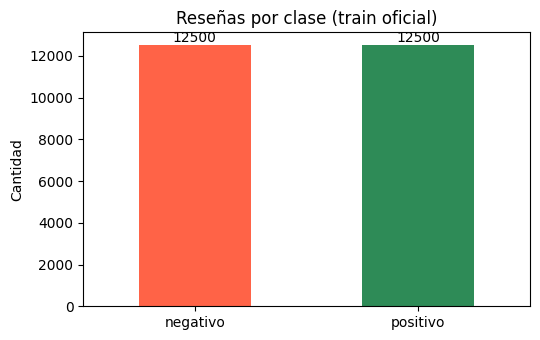

In [4]:
# (a) Balance de clases
eda = pd.DataFrame({"partición": ["train"] * len(train_raw) + ["test"] * len(test_raw),
                    "clase": [CLASS_NAMES[l] for l in np.concatenate([train_labels, test_labels])]})
display(pd.crosstab(eda["partición"], eda["clase"], margins=True))

counts = pd.Series([CLASS_NAMES[l] for l in train_labels]).value_counts().reindex(CLASS_NAMES)
ax = counts.plot(kind="bar", figsize=(5.5, 3.5), color=["tomato", "seagreen"], rot=0)
ax.set_title("Reseñas por clase (train oficial)"); ax.set_ylabel("Cantidad")
for i, v in enumerate(counts.values): ax.text(i, v + 150, str(v), ha="center")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "distribucion_clases.png", dpi=150); plt.show()

,count,mean,std,min,25%,50%,75%,max
clase,,,,,,,,
negativo,12500.0,230.9,166.7,10.0,128.0,174.0,278.0,1522.0
positivo,12500.0,236.7,180.5,12.0,125.0,174.0,291.0,2470.0


Percentiles 50/75/90/95/99: [174 284 458 598 913]
Reseñas con <= 250 palabras: 69.8%  (las más largas se truncan en el modelo)


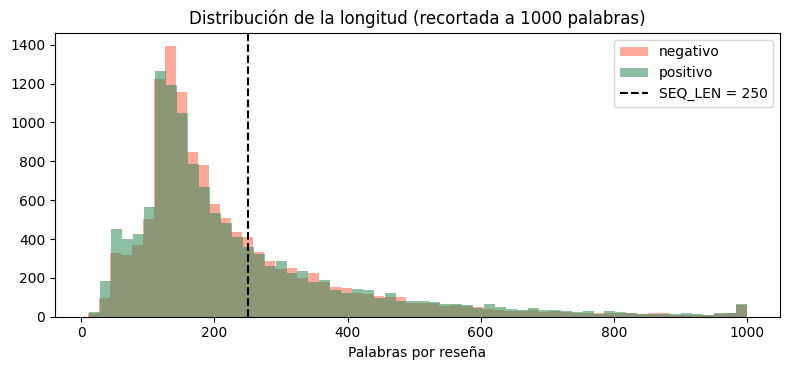

In [5]:
# (b) Longitud de las reseñas (en palabras)
n_words = np.array([len(t.split()) for t in train_raw])
len_df = pd.DataFrame({"n_palabras": n_words, "clase": [CLASS_NAMES[l] for l in train_labels]})
display(len_df.groupby("clase")["n_palabras"].describe().round(1))
pcts = np.percentile(n_words, [50, 75, 90, 95, 99])
print("Percentiles 50/75/90/95/99:", pcts.astype(int))
print(f"Reseñas con <= {SEQ_LEN} palabras: {(n_words <= SEQ_LEN).mean():.1%}  (las más largas se truncan en el modelo)")

fig, ax = plt.subplots(figsize=(8, 3.8))
for name, color in zip(CLASS_NAMES, ["tomato", "seagreen"]):
    ax.hist(np.clip(len_df.loc[len_df.clase == name, "n_palabras"], 0, 1000), bins=60, alpha=.55, label=name, color=color)
ax.axvline(SEQ_LEN, color="black", ls="--", label=f"SEQ_LEN = {SEQ_LEN}")
ax.set_title("Distribución de la longitud (recortada a 1000 palabras)"); ax.set_xlabel("Palabras por reseña"); ax.legend()
plt.tight_layout(); plt.savefig(FIGURES_DIR / "longitud_resenas.png", dpi=150); plt.show()

Reseñas duplicadas dentro del train: 96
Textos idénticos presentes en train y test: 123
Reseñas con etiquetas HTML <br /> en el train: 14665 (58.7%)  -> hay que limpiarlas


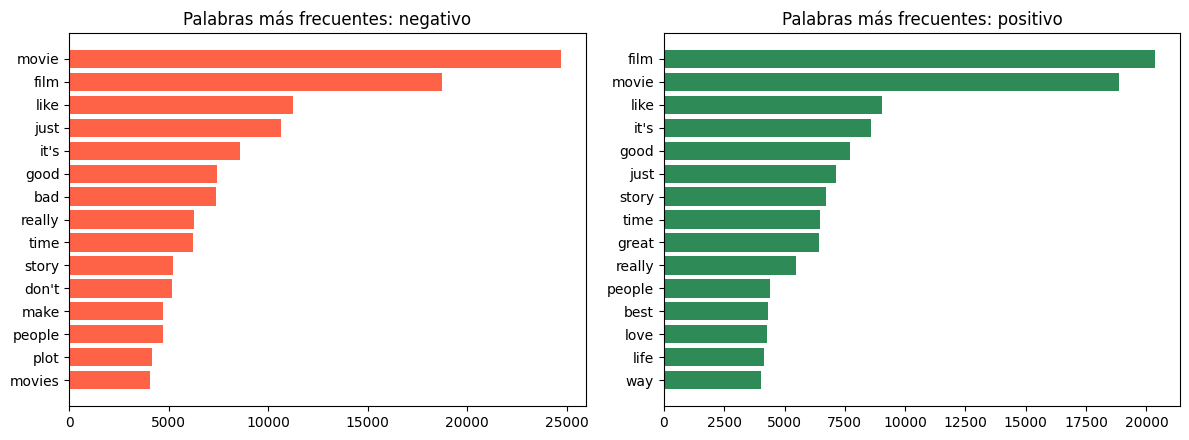

In [6]:
# (c) Duplicados y solapamiento, (d) ruido HTML
print("Reseñas duplicadas dentro del train:", pd.Series(train_raw).duplicated().sum())
print("Textos idénticos presentes en train y test:", len(set(train_raw) & set(test_raw)))
with_br = sum("<br />" in t for t in train_raw)
print(f"Reseñas con etiquetas HTML <br /> en el train: {with_br} ({with_br / len(train_raw):.1%})  -> hay que limpiarlas")

# (e) Palabras más frecuentes por clase (sin stopwords ni etiquetas)
def top_words(texts, n=15):
    c = Counter()
    for t in texts:
        t = re.sub(r"<[^>]+>", " ", t).lower()
        c.update(w for w in re.findall(r"[a-z']+", t) if w not in ENGLISH_STOP_WORDS and len(w) > 2)
    return c.most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (lab, name, color) in zip(axes, [(0, "negativo", "tomato"), (1, "positivo", "seagreen")]):
    tw = top_words([t for t, l in zip(train_raw, train_labels) if l == lab])
    ax.barh([w for w, _ in tw][::-1], [c for _, c in tw][::-1], color=color)
    ax.set_title(f"Palabras más frecuentes: {name}")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "palabras_frecuentes.png", dpi=150); plt.show()

In [7]:
# (f) Ejemplos
rng = np.random.default_rng(SEED)
for lab in (0, 1):
    print(f"--- Ejemplos de reseñas {CLASS_NAMES[lab].upper()} ---")
    for i in rng.choice(np.where(train_labels == lab)[0], 2, replace=False):
        print("•", train_raw[i][:300].replace("\n", " "), "...\n")

--- Ejemplos de reseñas NEGATIVO ---
• How do I begin? This movie is probably one of the worst movies I have ever seen .It has no redeemable qualities .I just sat through this movie and it was a struggle.It failed to get even a single smile on my face.I find it hard to believe that anyone would distribute this horrible film. I felt that  ...

• Admittedly, I didn't have high expectations of "Corky Romano." But then again, who did? However, I felt it deserved the benefit of the doubt. I had no high hopes of "Joe Dirt" either--another recent comedy starring an SNL cast member--and I ended up being pleasantly surprised. But this film is just  ...

--- Ejemplos de reseñas POSITIVO ---
• Delightful film directed by some of the best directors in the industry today. The film is also casting some of the great actors of our time, not just from France but from everywhere.<br /><br />My favorite segments:<br /><br />14th arrondissement: Carol (Margo Martindale), from Denver, comes to Pari ...

• 

**Observaciones del análisis exploratorio**
- Las clases están **balanceadas** (50 % / 50 %), por lo que la *accuracy* es una métrica válida; aun así se reportan precisión, recall, F1 y AUC.
- La longitud de las reseñas es **muy variable** y tiene cola larga. Se fija una longitud de **250 tokens**: las más cortas se rellenan (padding) y las más largas se truncan.
- El texto contiene **etiquetas HTML** (`<br />`) que no aportan sentimiento y deben eliminarse.
- Las palabras más frecuentes de ambas clases se parecen mucho (por ejemplo "movie", "film"): el sentimiento no depende solo de palabras sueltas, sino de su contexto. Es una de las razones para usar una red recurrente.

## 3. Limpieza y preprocesamiento

1. **Limpieza (en Python):** se eliminan etiquetas HTML y se normalizan los espacios (`clean_text`).
2. **Estandarización (dentro del modelo):** la capa `TextVectorization` convierte a minúsculas y elimina signos de puntuación.
3. **Tokenización y vocabulario:** cada palabra se convierte en un entero; se conservan las **20.000 palabras más frecuentes** del conjunto de entrenamiento y el resto se marca como desconocido (`[UNK]`).
4. **Longitud fija:** secuencias de 250 tokens (padding / truncado).

Como `TextVectorization` forma parte del modelo guardado, la app Streamlit recibe **texto crudo** y aplica exactamente el mismo preprocesamiento del entrenamiento.

In [8]:
_TAGS, _SPACES = re.compile(r"<[^>]+>"), re.compile(r"\s+")
def clean_text(text):
    text = _TAGS.sub(" ", str(text))
    return _SPACES.sub(" ", text).strip()

i = next(k for k, t in enumerate(train_raw) if "<br />" in t)
print("ANTES  :", train_raw[i][:220].replace("\n", " "))
print("DESPUÉS:", clean_text(train_raw[i])[:220])

train_clean = [clean_text(t) for t in train_raw]
test_clean  = [clean_text(t) for t in test_raw]
print("\nReseñas con etiquetas HTML tras la limpieza:", sum("<br" in t for t in train_clean + test_clean))

ANTES  : Airport '77 starts as a brand new luxury 747 plane is loaded up with valuable paintings & such belonging to rich businessman Philip Stevens (James Stewart) who is flying them & a bunch of VIP's to his estate in preparati
DESPUÉS: Airport '77 starts as a brand new luxury 747 plane is loaded up with valuable paintings & such belonging to rich businessman Philip Stevens (James Stewart) who is flying them & a bunch of VIP's to his estate in preparati

Reseñas con etiquetas HTML tras la limpieza: 0


## 4. División en entrenamiento, validación y prueba
- **Prueba:** el conjunto de **prueba oficial** del dataset (25.000 reseñas). No se usa para entrenar ni para ajustar nada.
- **Entrenamiento / validación:** el train oficial se divide de forma **estratificada** en 80 % / 20 % con semilla fija. La validación guía el entrenamiento (early stopping, ajuste del learning rate).
- El **vocabulario se aprende solo con el conjunto de entrenamiento** para evitar fuga de información.

In [9]:
x_train, x_val, y_train, y_val = train_test_split(
    train_clean, train_labels, test_size=VAL_FRAC, stratify=train_labels, random_state=SEED)
x_test, y_test = test_clean, test_labels

split_df = pd.DataFrame({
    "negativo": [(y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    "positivo": [(y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()]},
    index=["train", "val", "test"])
split_df["total"] = split_df.sum(axis=1)
display(split_df)

def make_ds(texts, labels, training):
    ds = tf.data.Dataset.from_tensor_slices((tf.constant(texts), labels.astype("float32")))
    if training:
        ds = ds.shuffle(min(len(texts), 20000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(x_train, y_train, True), make_ds(x_val, y_val, False), make_ds(x_test, y_test, False)

,negativo,positivo,total
train,10000,10000,20000
val,2500,2500,5000
test,12500,12500,25000


## 5. Vectorización del texto
Se crea la capa `TextVectorization` y se **adapta únicamente con el conjunto de entrenamiento** (aprende el vocabulario).

In [10]:
vectorizer = layers.TextVectorization(max_tokens=MAX_TOKENS, output_mode="int",
                                      output_sequence_length=SEQ_LEN, name="vectorizacion")
vectorizer.adapt(tf.data.Dataset.from_tensor_slices(tf.constant(x_train)).batch(256))
vocab = vectorizer.get_vocabulary()
print("Tamaño del vocabulario:", len(vocab))
print("Primeras 15 palabras (más frecuentes):", vocab[:15])

sample = x_train[0]
ids = vectorizer(tf.constant([sample]))[0].numpy()
print("\nTexto :", sample[:150], "...")
print("IDs   :", ids[:20], "...")
print("Decod.:", " ".join(vocab[k] for k in ids[:20]))

# Cobertura del vocabulario sobre la validación (palabras conocidas / total)
def tokens(t): return t.lower().translate(str.maketrans("", "", string.punctuation)).split()
vset = set(vocab)
toks = [w for t in x_val[:2000] for w in tokens(t)]
print(f"\nCobertura del vocabulario en validación: {np.mean([w in vset for w in toks]):.1%} de las palabras")

Tamaño del vocabulario: 20000
Primeras 15 palabras (más frecuentes): ['', '[UNK]', np.str_('the'), np.str_('and'), np.str_('a'), np.str_('of'), np.str_('to'), np.str_('is'), np.str_('in'), np.str_('it'), np.str_('i'), np.str_('this'), np.str_('that'), np.str_('was'), np.str_('as')]

Texto : Many reviews I've read reveals that most people tend to like Part One better than Part Two. I feel exactly the opposite. Part One played around a bit  ...
IDs   : [ 105  820  198  319 2728   12   87   77 2372    6   38  167   28  123
   71  167  104   10  232  591] ...
Decod.: many reviews ive read reveals that most people tend to like part one better than part two i feel exactly

Cobertura del vocabulario en validación: 96.4% de las palabras


## 6. Construcción de la red neuronal
Arquitectura:

`Texto crudo → TextVectorization (250 tokens) → Embedding(20000 → 64, mask_zero) → Bidirectional(LSTM(64)) → Dropout(0.4) → Dense(32, ReLU) → Dropout(0.3) → Dense(1, sigmoide)`

- **Embedding:** representa cada palabra como un vector de 64 dimensiones que se aprende durante el entrenamiento. `mask_zero=True` hace que la red ignore el relleno (padding).
- **LSTM bidireccional:** lee la reseña en ambos sentidos, de modo que cada palabra se interpreta con el contexto anterior y posterior. La LSTM conserva información a largo plazo mediante sus compuertas, lo que mitiga el problema de desvanecimiento del gradiente de las RNN simples.
- **Dropout:** regularización contra el sobreajuste.
- **Salida sigmoide:** probabilidad de que la reseña sea **positiva**. Si es ≥ 0,5 se predice positiva; la confianza es la probabilidad de la clase predicha.
- **Pérdida:** `binary_crossentropy`. **Optimizador:** Adam. **Métricas:** accuracy y AUC.

In [11]:
def build_model():
    inputs = keras.Input(shape=(), dtype="string", name="texto")
    x = vectorizer(inputs)
    x = layers.Embedding(MAX_TOKENS, EMBED_DIM, mask_zero=True, name="embedding")(x)
    x = layers.Bidirectional(layers.LSTM(LSTM_UNITS, dropout=0.2), name="bilstm")(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="prob_positivo")(x)
    model = keras.Model(inputs, outputs, name="rnn_sentimiento")
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model

model = build_model()
model.summary()

Model: "rnn_sentimiento"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ texto (InputLayer)  │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vectorizacion       │ (None, 250)       │          0 │ texto[0][0]       │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 250, 64)   │  1,280,000 │ vectorizacion[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 250)       │          0 │ vectorizacion[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm              │ (None, 128)       │     66,048 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bilstm[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      4,128 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ prob_positivo       │ (None, 1)         │         33 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,350,209 (5.15 MB)

 Trainable params: 1,350,209 (5.15 MB)

 Non-trainable params: 0 (0.00 B)

## 7. Entrenamiento y gráficas
- **EarlyStopping** (paciencia 3, sobre `val_loss`): detiene el entrenamiento cuando deja de mejorar y **restaura los mejores pesos**. En texto es habitual que la red empiece a sobreajustar tras pocas épocas.
- **ReduceLROnPlateau:** reduce el learning rate a la mitad si `val_loss` no mejora.

In [12]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5, verbose=1),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)
hist = {k: [float(v) for v in vals] for k, vals in history.history.items()}

Epoch 1/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 17s 32ms/step - accuracy: 0.7768 - auc: 0.8691 - loss: 0.4517 - val_accuracy: 0.8550 - val_auc: 0.9388 - val_loss: 0.3445 - learning_rate: 0.0010
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.9160 - auc: 0.9675 - loss: 0.2270 - val_accuracy: 0.8642 - val_auc: 0.9421 - val_loss: 0.3146 - learning_rate: 0.0010
Epoch 3/15
312/313 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9544 - auc: 0.9881 - loss: 0.1331
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.9498 - auc: 0.9870 - loss: 0.1409 - val_accuracy: 0.8688 - val_auc: 0.9417 - val_loss: 0.3614 - learning_rate: 0.0010
Epoch 4/15
311/313 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9822 - auc: 0.9969 - loss: 0.0595
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.9815 - auc: 0.9967 - loss: 0.0600 - val_accu

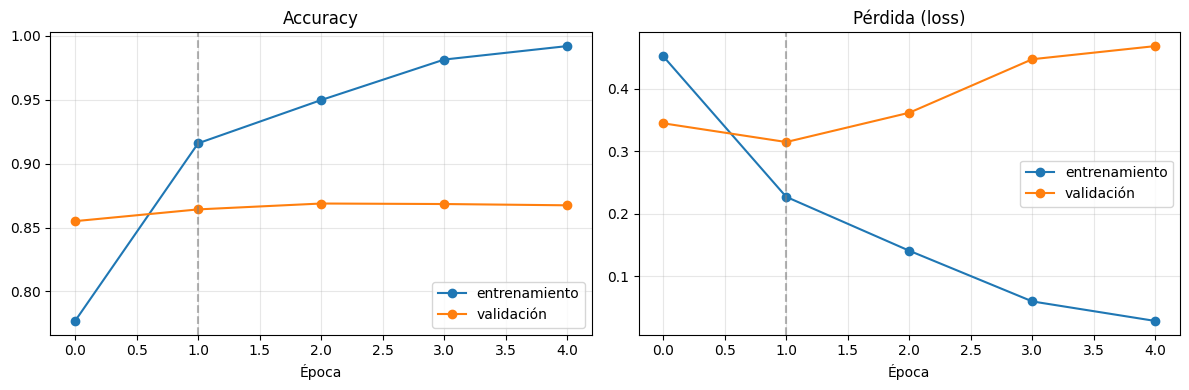

Épocas ejecutadas: 5 | mejor época (menor val_loss): 2
En la mejor época -> train acc 0.9160 | val acc 0.8642


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, title in zip(axes, ("accuracy", "loss"), ("Accuracy", "Pérdida (loss)")):
    ax.plot(hist[key], label="entrenamiento", marker="o"); ax.plot(hist["val_" + key], label="validación", marker="o")
    ax.set_title(title); ax.set_xlabel("Época"); ax.grid(alpha=.3); ax.legend()
best_ep = int(np.argmin(hist["val_loss"]))
for ax in axes: ax.axvline(best_ep, color="gray", ls="--", alpha=.6)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "curvas_entrenamiento.png", dpi=150); plt.show()

print(f"Épocas ejecutadas: {len(hist['loss'])} | mejor época (menor val_loss): {best_ep + 1}")
print(f"En la mejor época -> train acc {hist['accuracy'][best_ep]:.4f} | val acc {hist['val_accuracy'][best_ep]:.4f}")

## 8. Evaluación con métricas apropiadas
Se evalúa sobre el **conjunto de prueba oficial** (25.000 reseñas que el modelo nunca vio).

- **Accuracy:** válida porque las clases están balanceadas.
- **Precisión, recall y F1:** muestran el equilibrio entre falsos positivos y falsos negativos.
- **AUC-ROC:** mide qué tan bien separa las clases en todos los umbrales posibles, no solo en 0,5.
- **Matriz de confusión:** cuántas reseñas de cada clase se clasifican bien o mal.

In [14]:
probs = model.predict(tf.constant(x_test), batch_size=256, verbose=0).ravel()
y_pred = (probs >= THRESHOLD).astype(int)

test_loss = float(keras.losses.binary_crossentropy(y_test.astype("float32"), probs).numpy().mean())
acc = accuracy_score(y_test, y_pred); prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred); f1 = f1_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro"); auc = roc_auc_score(y_test, probs)

print(f"Test loss  : {test_loss:.4f}")
print(f"Accuracy   : {acc:.4f}")
print(f"Precisión  : {prec:.4f}  (clase positiva)")
print(f"Recall     : {rec:.4f}  (clase positiva)")
print(f"F1         : {f1:.4f}  (clase positiva) | F1 macro: {f1_macro:.4f}")
print(f"AUC-ROC    : {auc:.4f}\n")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, zero_division=0))
report = classification_report(y_test, y_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0)

Test loss  : 0.3442
Accuracy   : 0.8506
Precisión  : 0.8830  (clase positiva)
Recall     : 0.8083  (clase positiva)
F1         : 0.8440  (clase positiva) | F1 macro: 0.8503
AUC-ROC    : 0.9328

              precision    recall  f1-score   support

    negativo       0.82      0.89      0.86     12500
    positivo       0.88      0.81      0.84     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



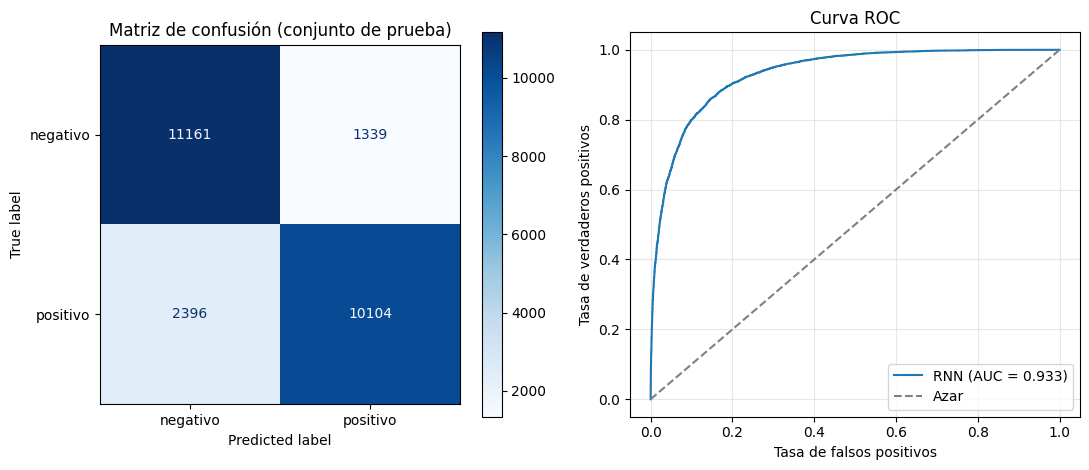

Falsos positivos (negativas predichas como positivas): 1339
Falsos negativos (positivas predichas como negativas): 2396


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASS_NAMES, cmap="Blues", ax=axes[0], values_format="d")
axes[0].set_title("Matriz de confusión (conjunto de prueba)")
fpr, tpr, _ = roc_curve(y_test, probs)
axes[1].plot(fpr, tpr, label=f"RNN (AUC = {auc:.3f})"); axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Azar")
axes[1].set_xlabel("Tasa de falsos positivos"); axes[1].set_ylabel("Tasa de verdaderos positivos")
axes[1].set_title("Curva ROC"); axes[1].grid(alpha=.3); axes[1].legend()
plt.tight_layout()
# versiones individuales para el README
f1_, a1 = plt.subplots(figsize=(5.5, 5)); ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASS_NAMES, cmap="Blues", ax=a1, values_format="d")
a1.set_title("Matriz de confusión (conjunto de prueba)"); f1_.tight_layout(); f1_.savefig(FIGURES_DIR / "matriz_confusion.png", dpi=150); plt.close(f1_)
f2_, a2 = plt.subplots(figsize=(5.5, 5)); a2.plot(fpr, tpr, label=f"RNN (AUC = {auc:.3f})"); a2.plot([0, 1], [0, 1], "--", color="gray", label="Azar")
a2.set_xlabel("Tasa de falsos positivos"); a2.set_ylabel("Tasa de verdaderos positivos"); a2.set_title("Curva ROC (conjunto de prueba)"); a2.grid(alpha=.3); a2.legend()
f2_.tight_layout(); f2_.savefig(FIGURES_DIR / "curva_roc.png", dpi=150); plt.close(f2_)
plt.show()

cm = confusion_matrix(y_test, y_pred)
print(f"Falsos positivos (negativas predichas como positivas): {cm[0, 1]}")
print(f"Falsos negativos (positivas predichas como negativas): {cm[1, 0]}")

## 9. Comparación con una línea base clásica
Para saber si la red recurrente realmente aporta, se compara con un modelo **clásico y sencillo**: TF-IDF (unigramas y bigramas) + regresión logística, entrenado con los mismos datos de entrenamiento y evaluado en el mismo conjunto de prueba.

> Esta comparación es una referencia. El objetivo del trabajo es la RNN; el resultado se reporta tal como sale, sin ajustarlo.

In [16]:
tfidf = TfidfVectorizer(max_features=MAX_TOKENS, ngram_range=(1, 2), sublinear_tf=True)
Xtr = tfidf.fit_transform(x_train); Xte = tfidf.transform(x_test)
base = LogisticRegression(max_iter=1000).fit(Xtr, y_train)
base_probs = base.predict_proba(Xte)[:, 1]; base_pred = (base_probs >= THRESHOLD).astype(int)
baseline = {"accuracy": accuracy_score(y_test, base_pred), "f1": f1_score(y_test, base_pred),
            "roc_auc": roc_auc_score(y_test, base_probs)}
comp = pd.DataFrame({"LSTM bidireccional": [acc, f1, auc], "TF-IDF + Regresión logística": list(baseline.values())},
                    index=["Accuracy", "F1 (positiva)", "AUC-ROC"]).round(4)
display(comp)

,LSTM bidireccional,TF-IDF + Regresión logística
Accuracy,0.8506,0.8973
F1 (positiva),0.8440,0.8978
AUC-ROC,0.9328,0.9611


## 10. Predicciones de prueba (12 reseñas) y análisis de errores
Barra verde = acierto, roja = error. La barra indica la probabilidad de que la reseña sea **positiva** (la línea punteada es el umbral 0,5).

,texto,real,predicho,prob_positivo,confianza_%,acierto
0,"Most American remakes of European films are pretty poor, but this is in a league of its own. In fact this migh...",negativo,negativo,0.0189,98.11,True
1,"I would bet a month's salary ""The Magnificent Seven Returns"" (MSR) was made-for-TV. Other reviewers attest tha...",negativo,negativo,0.0938,90.62,True
2,"Directed by Michael Curtiz, Four Daughters is about four musically gifted sisters, their suitors, and their fa...",positivo,negativo,0.4363,56.37,False
3,"This film had everything i need in a film: - Women, skateboarding, violence, music by H.I.M and Tony Hawk!!! t...",positivo,positivo,0.9372,93.72,True
4,"One of the funniest films I ever saw in the theater back in the early '70s, and sadly, it's only been on TV a ...",positivo,positivo,0.9926,99.26,True
5,"I stumbled across this film while channel surfing, and was blown away. It was being broadcast on a lesser know...",positivo,positivo,0.9975,99.75,True
6,I am having a hard time finding the words to explain just how much I detested this movie. The historical trial...,negativo,negativo,0.0100,99.00,True
7,"Eleven years ago, Stanley Ipkiss released his true inner self and became the hero of Edge City by finding and ...",negativo,positivo,0.9602,96.02,False
8,"I loved so much last Bellocchio's movie, the masterpiece ""L'Ora di Religione"". It had a great screenplay, grea...",negativo,negativo,0.4536,54.64,True
9,Love In Limbo is my all-time favoirite movie. (set in W.A) It is hilairious and has an excellent cast includin...,positivo,positivo,0.9576,95.76,True


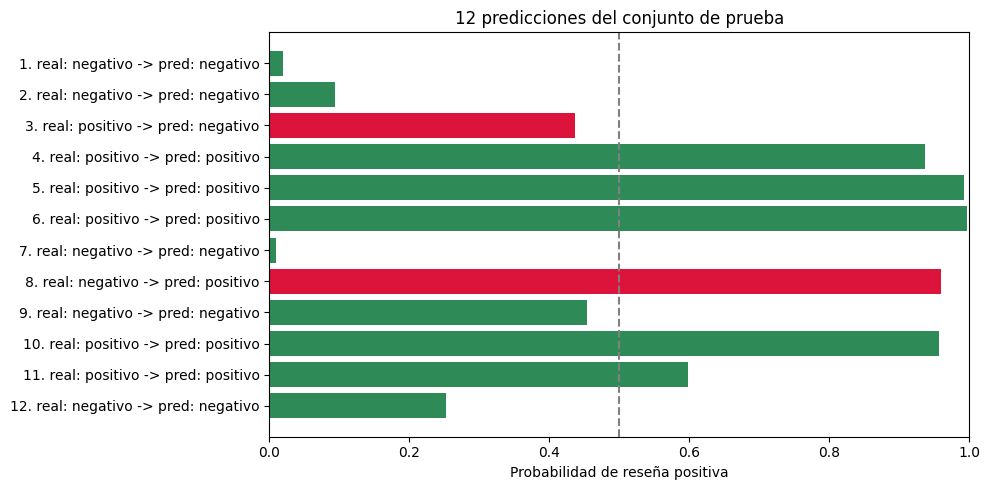

Aciertos en estas 12 reseñas: 10 de 12 (muestra ilustrativa; la métrica real es la del conjunto completo)


In [17]:
idx = np.random.default_rng(SEED).choice(len(x_test), size=12, replace=False)
rows = []
for i in idx:
    pred = int(probs[i] >= THRESHOLD)
    rows.append({"texto": x_test[i][:110] + "...", "real": CLASS_NAMES[y_test[i]], "predicho": CLASS_NAMES[pred],
                 "prob_positivo": round(float(probs[i]), 4),
                 "confianza_%": round(float(probs[i] if pred else 1 - probs[i]) * 100, 2),
                 "acierto": bool(pred == y_test[i])})
pred_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120)
display(pred_df)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(range(12), pred_df["prob_positivo"], color=["seagreen" if ok else "crimson" for ok in pred_df["acierto"]])
ax.set_yticks(range(12)); ax.set_yticklabels([f"{k+1}. real: {r} -> pred: {p}" for k, (r, p) in enumerate(zip(pred_df["real"], pred_df["predicho"]))])
ax.axvline(THRESHOLD, ls="--", color="gray"); ax.set_xlim(0, 1); ax.invert_yaxis()
ax.set_xlabel("Probabilidad de reseña positiva"); ax.set_title("12 predicciones del conjunto de prueba")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "predicciones_12.png", dpi=150); plt.show()
print(f"Aciertos en estas 12 reseñas: {pred_df['acierto'].sum()} de 12 (muestra ilustrativa; la métrica real es la del conjunto completo)")

In [18]:
# Análisis de errores: las equivocaciones con mayor confianza
wrong = np.where(y_pred != y_test)[0]
print(f"Errores en test: {len(wrong)} de {len(y_test)}\n")
worst = wrong[np.argsort(-np.abs(probs[wrong] - 0.5))][:5]
for i in worst:
    print(f"Real: {CLASS_NAMES[y_test[i]]} | Predicho: {CLASS_NAMES[y_pred[i]]} | P(positivo) = {probs[i]:.3f}")
    print("  ", x_test[i][:350], "...\n")

Errores en test: 3735 de 25000

Real: negativo | Predicho: positivo | P(positivo) = 0.997
   This movie was pure genius. John Waters is brilliant. It is hilarious and I am not sick of it even after seeing it about 20 times since I bought it a few months ago. The acting is great, although Ricki Lake could have been better. And Johnny Depp is magnificent. He is such a beautiful man and a very talented actor. And seeing most of Johnny's movie ...

Real: negativo | Predicho: positivo | P(positivo) = 0.997
   Masterpiece. Carrot Top blows the screen away. Never has one movie captured the essence of the human spirit quite like "Chairman of the Board." 10/10... don't miss this instant classic. ...

Real: negativo | Predicho: positivo | P(positivo) = 0.997
   This is definitely one of the best Kung fu movies in the history of Cinema. The screenplay is really well done (which is not often the case for this type of movies) and you can see that Chuck (in one of his first role)is a great actor. Th

## 11. Guardado del modelo
Se guarda el modelo completo (vectorizador + embedding + LSTM + capas densas) en formato `.keras`, junto con el historial, las métricas y las predicciones de ejemplo. La app Streamlit carga exactamente este archivo.

In [19]:
model.save(MODEL_PATH)
(REPORTS_DIR / "history.json").write_text(json.dumps(hist, indent=2))
pred_df.to_csv(REPORTS_DIR / "predicciones_12.csv", index=False)
metrics = {
    "test_loss": test_loss, "test_accuracy": float(acc), "precision_positivo": float(prec),
    "recall_positivo": float(rec), "f1_positivo": float(f1), "f1_macro": float(f1_macro),
    "roc_auc": float(auc), "n_test": int(len(y_test)), "confusion_matrix": cm.tolist(),
    "classification_report": report,
    "baseline_tfidf_logreg": {k: float(v) for k, v in baseline.items()},
    "versions": {"tensorflow": tf.__version__, "keras": keras.__version__, "python": sys.version.split()[0]},
}
(REPORTS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))
print("Modelo guardado:", MODEL_PATH, f"({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")

# Verificación: el modelo recargado debe dar las mismas probabilidades
reloaded = keras.models.load_model(MODEL_PATH)
p_old = model.predict(tf.constant(x_test[:200]), verbose=0).ravel()
p_new = reloaded.predict(tf.constant(x_test[:200]), verbose=0).ravel()
diff = float(np.abs(p_old - p_new).max())
print(f"Diferencia máxima entre el modelo original y el recargado: {diff:.2e}")
assert diff < 1e-4, "El modelo recargado no coincide con el original"

# Predicción sobre texto nuevo con el modelo recargado (lo mismo que hace la app)
for frase in ["This movie was absolutely wonderful, I loved every minute of it.",
              "A boring and terrible film. I want my money back."]:
    p = float(reloaded(tf.constant([clean_text(frase)]), training=False).numpy()[0][0])
    print(f"{CLASS_NAMES[int(p >= THRESHOLD)]:>8} (P positivo = {p:.3f}) <- {frase}")

Modelo guardado: /content/models/sentiment_rnn.keras (16.6 MB)
Diferencia máxima entre el modelo original y el recargado: 0.00e+00
positivo (P positivo = 0.975) <- This movie was absolutely wonderful, I loved every minute of it.
negativo (P positivo = 0.008) <- A boring and terrible film. I want my money back.


In [20]:
# Resumen en Markdown con los resultados REALES de esta ejecución (para pegar en el README)
cm_l = cm.tolist()
lines = [
    "Resultados reales sobre el **conjunto de prueba oficial** (%d reseñas que el modelo nunca vio)." % len(y_test), "",
    "| Métrica | Valor |", "|---|---|",
    f"| Accuracy | **{acc*100:.2f}%** |", f"| Precisión (positiva) | {prec*100:.2f}% |",
    f"| Recall (positiva) | {rec*100:.2f}% |", f"| F1 (positiva) | **{f1*100:.2f}%** |",
    f"| F1 macro | {f1_macro*100:.2f}% |", f"| AUC-ROC | {auc:.4f} |", f"| Pérdida (loss) | {test_loss:.3f} |", "",
    "| Clase | Precisión | Recall | F1 | Reseñas |", "|---|---|---|---|---|",
]
for c in CLASS_NAMES:
    r = report[c]; lines.append(f"| {c} | {r['precision']*100:.1f}% | {r['recall']*100:.1f}% | {r['f1-score']*100:.1f}% | {int(r['support'])} |")
lines += ["", f"Matriz de confusión: {cm_l[0][0]} negativas bien clasificadas, {cm_l[0][1]} negativas predichas como positivas, "
          f"{cm_l[1][0]} positivas predichas como negativas, {cm_l[1][1]} positivas bien clasificadas.", "",
          f"Entrenamiento: {len(hist['loss'])} épocas ejecutadas, mejor época {best_ep + 1} (train acc {hist['accuracy'][best_ep]*100:.2f}% vs val acc {hist['val_accuracy'][best_ep]*100:.2f}%).", "",
          "| Comparación en test | LSTM bidireccional | TF-IDF + Reg. logística |", "|---|---|---|",
          f"| Accuracy | {acc*100:.2f}% | {baseline['accuracy']*100:.2f}% |", f"| F1 (positiva) | {f1*100:.2f}% | {baseline['f1']*100:.2f}% |",
          f"| AUC-ROC | {auc:.4f} | {baseline['roc_auc']:.4f} |", "",
          "Versiones: Python %s, TensorFlow %s, Keras %s." % (sys.version.split()[0], tf.__version__, keras.__version__)]
(REPORTS_DIR / "RESULTADOS.md").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines))

Resultados reales sobre el **conjunto de prueba oficial** (25000 reseñas que el modelo nunca vio).

| Métrica | Valor |
|---|---|
| Accuracy | **85.06%** |
| Precisión (positiva) | 88.30% |
| Recall (positiva) | 80.83% |
| F1 (positiva) | **84.40%** |
| F1 macro | 85.03% |
| AUC-ROC | 0.9328 |
| Pérdida (loss) | 0.344 |

| Clase | Precisión | Recall | F1 | Reseñas |
|---|---|---|---|---|
| negativo | 82.3% | 89.3% | 85.7% | 12500 |
| positivo | 88.3% | 80.8% | 84.4% | 12500 |

Matriz de confusión: 11161 negativas bien clasificadas, 1339 negativas predichas como positivas, 2396 positivas predichas como negativas, 10104 positivas bien clasificadas.

Entrenamiento: 5 épocas ejecutadas, mejor época 2 (train acc 91.60% vs val acc 86.42%).

| Comparación en test | LSTM bidireccional | TF-IDF + Reg. logística |
|---|---|---|
| Accuracy | 85.06% | 89.73% |
| F1 (positiva) | 84.40% | 89.78% |
| AUC-ROC | 0.9328 | 0.9611 |

Versiones: Python 3.13.15, TensorFlow 2.21.0, Keras 3.13.2.


In [21]:
# Empaquetar los resultados de Colab para descargarlos y subirlos al repositorio
zip_path = BASE / "resultados_colab.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in (MODELS_DIR, REPORTS_DIR):
        for f in folder.rglob("*"):
            if f.is_file():
                z.write(f, f.relative_to(BASE))
print("Creado:", zip_path)
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("(No estás en Colab: los archivos ya están en models/ y reports/)")

Creado: /content/resultados_colab.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Resumen automático y conclusiones
La celda siguiente redacta el resumen con los **valores reales** de esta ejecución.

In [22]:
print(f"""RESULTADOS FINALES
- Reseñas: train {len(x_train)}, val {len(x_val)}, test {len(x_test)}
- Épocas ejecutadas: {len(hist['loss'])}; mejor época: {best_ep + 1}
- Test -> accuracy {acc*100:.2f}% | F1 {f1*100:.2f}% | AUC {auc:.4f}
- Brecha train-val en la mejor época: {(hist['accuracy'][best_ep] - hist['val_accuracy'][best_ep])*100:+.2f} puntos de accuracy
- Línea base TF-IDF + regresión logística -> accuracy {baseline['accuracy']*100:.2f}%
- Diferencia RNN - línea base: {(acc - baseline['accuracy'])*100:+.2f} puntos de accuracy
- Errores en test: {len(wrong)} de {len(y_test)} ({len(wrong)/len(y_test):.1%})""")

RESULTADOS FINALES
- Reseñas: train 20000, val 5000, test 25000
- Épocas ejecutadas: 5; mejor época: 2
- Test -> accuracy 85.06% | F1 84.40% | AUC 0.9328
- Brecha train-val en la mejor época: +5.18 puntos de accuracy
- Línea base TF-IDF + regresión logística -> accuracy 89.73%
- Diferencia RNN - línea base: -4.67 puntos de accuracy
- Errores en test: 3735 de 25000 (14.9%)


### Conclusiones
- Se construyó una **LSTM bidireccional** con vectorización integrada, entrenada con early stopping y ajuste de learning rate sobre reseñas reales de IMDB. Las cifras finales (accuracy, F1, AUC, brecha entre entrenamiento y validación y comparación con la línea base) están en el resumen automático de arriba y en `reports/metrics.json`.
- Incluir la vectorización **dentro del modelo** garantiza que la app aplique exactamente el mismo preprocesamiento que el entrenamiento: recibe texto crudo.
- **Comparación con la línea base:** en este experimento el modelo clásico TF-IDF + regresión logística obtuvo **mejor accuracy** que la LSTM (89,73 % frente a 85,06 % en el conjunto de prueba). Es un resultado conocido en IMDB: las reseñas son largas y los n-gramas TF-IDF capturan bien el sentimiento. Una posible explicación es que la LSTM **sobreajusta muy rápido** (ver curvas) y se quedó con los pesos de la época 2; no se probaron otras configuraciones, así que no se puede afirmar la causa.
- **Sobreajuste:** el accuracy de entrenamiento sube hasta ≈99 % mientras el de validación se estanca en ≈87 % y la pérdida de validación aumenta a partir de la época 2. El *early stopping* con restauración de pesos limita el problema, pero no lo elimina.
- **Sesgo hacia la clase negativa:** el recall es 89,3 % en reseñas negativas y 80,8 % en positivas (2.396 positivas clasificadas como negativas frente a 1.339 en sentido contrario).
- El análisis de errores muestra el tipo de reseñas que se confunden; suelen ser reseñas **ambiguas, irónicas o que mezclan opiniones**.

### Limitaciones
- El modelo solo entiende **inglés** y el **dominio de reseñas de películas**. En otro idioma o con otro tipo de texto la predicción no es fiable (la app avisa cuando muchas palabras no están en el vocabulario).
- Las secuencias se **truncan a 250 tokens**: en reseñas muy largas se pierde información del final.
- La probabilidad de salida no es una medida perfecta de certeza; puede haber confianza alta en errores (ironía, sarcasmo).

### Mejoras futuras
- Embeddings preentrenados (GloVe) o modelos *Transformer* preentrenados (p. ej. DistilBERT).
- Búsqueda sistemática de hiperparámetros y una versión multilingüe.
- Calibrar las probabilidades para que la confianza sea más fiable.